# Directed Hypergraph Sheaf Neural Networks

Some group interactions have a direction. A chemical reaction turns a *set* of reactants into a *set* of products, an email goes from one sender to several recipients, and a meeting's decision flows from its organizers to its attendees. A **directed hyperedge** captures this with a **tail set** $T(e)$ (where the interaction starts) and a **head set** $H(e)$ (where it arrives). **Directional Sheaf Hypergraph Networks** (DSHN; Mule et al., 2025) combine the hypergraph sheaves of notebook 8 with the complex phases of notebook 3 into a single Hermitian Laplacian that handles directed and undirected hypergraphs alike.

Like notebook 8, this is a **hands-on design notebook**. The data, the figures, and the reference computations are executable, while the neural layer is left as TODOs that the default cells never call.

### What You Will Learn
* How directed hyperedges generalize both directed edges and undirected hyperedges, and how a directed graph can be turned into a directed hypergraph.
* The **Directed Sheaf Hypergraph Laplacian**: a complex incidence matrix whose tail entries carry the phase $e^{-2\pi i q}$.
* How to build it densely and verify that it is Hermitian and positive semi-definite, reduces to the undirected sheaf hypergraph Laplacian at $q = 0$, recovers the magnetic Laplacian of notebook 3 on directed graphs, and is conjugated when every direction is reversed.
* How the imaginary part of the operator encodes the *net flow* between nodes.
* How to structure a directed sheaf hypergraph layer (TODO).

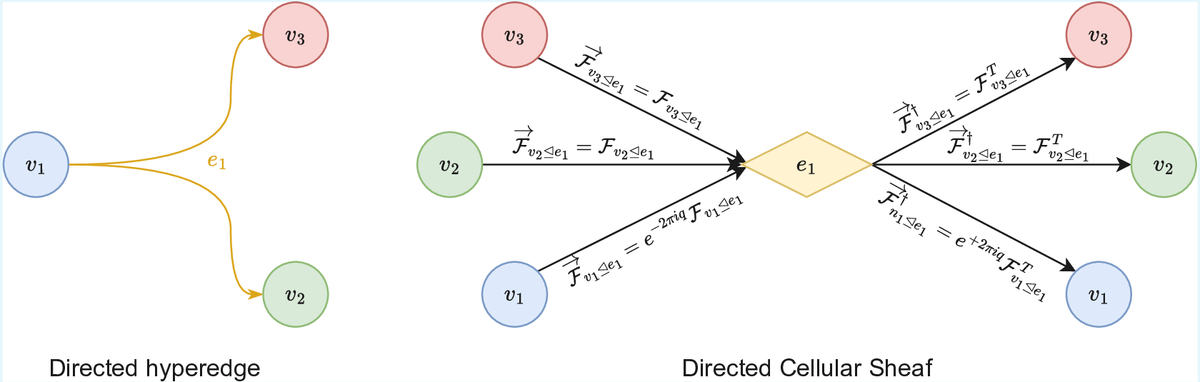

*Sheaves over a directed hyperedge. Left: a directed hyperedge e1 with tail v1 and heads v2, v3. Right: the Directed Cellular Sheaf, where each incidence has a restriction map into the hyperedge stalk; the tail node v1 is encoded through the phase e^{-2 pi i q}, which multiplies its otherwise directionless map, and the reverse (adjoint) maps carry the conjugate phase.*

<sub>Source: Mule et al. (2025), *Directional Sheaf Hypergraph Networks: Unifying Learning on Directed and Undirected Hypergraphs*, [arXiv:2510.04727](https://arxiv.org/abs/2510.04727), Fig. 1. Reproduced for teaching with attribution (CC BY 4.0).</sub>

## Table of Contents

1. [Introduction](#1-introduction)
2. [Environment Setup and Imports](#2-env-setup)
3. [Directed Hypergraphs](#3-directed-hypergraphs)
    * [Tails, Heads, and Graphs as Hypergraphs](#tails-heads)
    * [The Directed Sheaf Hypergraph Laplacian](#directed-laplacian)
4. [Dataset Pipeline](#4-dataset-pipeline)
5. [Reference Computations](#5-reference)
    * [Building the Directed Laplacian](#building)
    * [Properties and Special Cases](#properties)
    * [Charge, Spectrum, and Net Flow](#charge-and-flow)
6. [Model Backbone (TODO)](#6-backbone)
7. [Training Pipeline (TODO)](#7-training)
8. [Reproducibility and Exercises](#8-exercises)

<a id="1-introduction"></a>
# 1. Introduction

Notebook 8 showed that undirected hypergraph sheaves keep group identity and avoid oversmoothing. Notebook 3 showed that a complex phase $e^{i 2\pi q}$ on directed edges gives a Hermitian Laplacian that "sees" direction. DSHN combines the two ideas.
* Every incidence $(v, e)$ keeps its real restriction map $\mathcal{F}_{v \trianglelefteq e}$.
* If $v$ is in the **tail** of $e$, the map is multiplied by the phase $e^{-2\pi i q}$; head maps stay real.
* The Laplacian is built from this complex incidence structure exactly as in the undirected case, with a conjugate transpose instead of a transpose.

The result is one operator for directed graphs, undirected graphs, directed hypergraphs, and undirected hypergraphs: setting $q = 0$, or giving every hyperedge an empty tail, removes the direction and recovers the undirected model.

<a id="2-env-setup"></a>
# 2. Environment Setup and Imports

As in notebook 8, only PyTorch, NumPy, and Matplotlib are needed.

In [1]:
# =====================================================================
# 1. Standard Library & Repository Path
# =====================================================================
import random
import sys
import warnings
from pathlib import Path


def find_repo_root(start: Path | None = None) -> Path:
    """Find the repository root (the folder holding pyproject.toml and src/)."""
    start = (start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists() and (p / "src").exists():
            return p
    raise FileNotFoundError("Could not locate the repository")


REPO_ROOT = find_repo_root()
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

# =====================================================================
# 2. Core Scientific Libraries & Reproducibility
# =====================================================================
import matplotlib.pyplot as plt
import numpy as np
import torch

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)  # noqa: NPY002
torch.manual_seed(SEED)
torch.set_num_threads(1)

print("--- Environment Status ---")
print(f"Repository root: {REPO_ROOT}")
print(f"Python:  {sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")

--- Environment Status ---
Repository root: <repo>
Python:  3.13.12
PyTorch: 2.8.0


<a id="3-directed-hypergraphs"></a>
# 3. Directed Hypergraphs

<a id="tails-heads"></a>
### 3.1 Tails, Heads, and Graphs as Hypergraphs

A directed hyperedge is a pair $e = (T(e), H(e))$ of disjoint node sets; an undirected hyperedge is the special case $T(e) = \emptyset$, with all members treated alike. Directed graphs embed naturally: the DSHN paper turns a directed graph into a directed hypergraph by creating, for every node, one hyperedge whose tail is the node and whose head is its out-neighbourhood. This groups all of a node's outgoing interactions into a single higher-order relation.

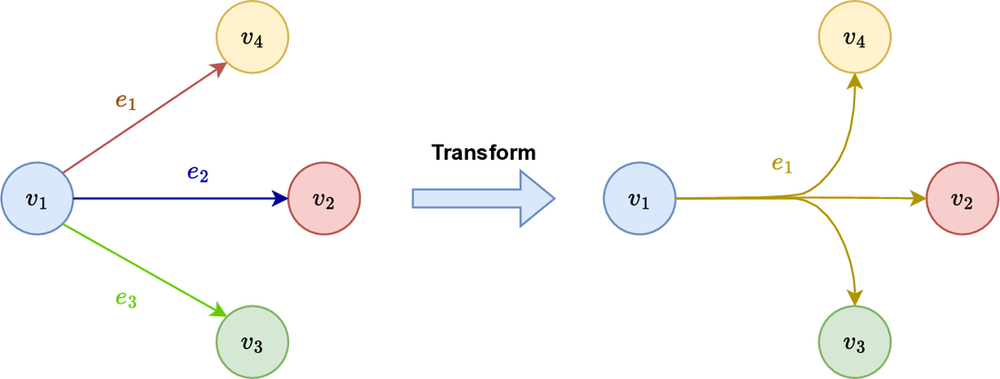

*Building a directed hyperedge from the out-neighbourhood of a node: node v1 points to v2, v3, and v4, so the construction yields one directed hyperedge e1 with tail set T(e1) = {v1} and head set H(e1) = {v2, v3, v4}.*

<sub>Source: Mule et al. (2025), *Directional Sheaf Hypergraph Networks: Unifying Learning on Directed and Undirected Hypergraphs*, [arXiv:2510.04727](https://arxiv.org/abs/2510.04727), appendix. Reproduced for teaching with attribution (CC BY 4.0).</sub>

In [2]:
# =====================================================================
# Directed graph -> directed hypergraph (one hyperedge per out-neighbourhood)
# =====================================================================
def out_neighbourhood_hyperedges(directed_edges, n):
    tails, heads = [], []
    for v in range(n):
        out = sorted(u for (s, u) in directed_edges if s == v)
        if out:
            tails.append([v])
            heads.append(out)
    return tails, heads


demo_edges = [(0, 1), (0, 2), (0, 3), (2, 3), (3, 1)]
demo_tails, demo_heads = out_neighbourhood_hyperedges(demo_edges, 4)
for t, h in zip(demo_tails, demo_heads, strict=True):
    print(f"hyperedge: tail {t} -> head {h}")

hyperedge: tail [0] -> head [1, 2, 3]
hyperedge: tail [2] -> head [3]
hyperedge: tail [3] -> head [1]


<a id="directed-laplacian"></a>
### 3.2 The Directed Sheaf Hypergraph Laplacian

For a charge $q \in \mathbb{R}$, define the complex **directional incidence** blocks

$$\mathbf{B}^{(q)}_{e u} = \begin{cases}\mathcal{F}_{u \trianglelefteq e} & u \in H(e)\\ e^{-2\pi i q}\,\mathcal{F}_{u \trianglelefteq e} & u \in T(e)\\ 0 & \text{otherwise.}\end{cases}$$

With the hyperedge degree matrix $\mathbf{D}_E = \operatorname{diag}(\delta_e I_d)$ and the node degree blocks $\mathbf{D}_u = \sum_{e \ni u}\vec{\mathcal{F}}_{u \trianglelefteq e}^{\dagger}\vec{\mathcal{F}}_{u \trianglelefteq e}$, the **Directed Sheaf Hypergraph Laplacian** is

$$\mathbf{L}^{\vec{\mathcal{F}}} = \mathbf{D}_V - \mathbf{B}^{(q)\dagger}\,\mathbf{D}_E^{-1}\,\mathbf{B}^{(q)}.$$

Entry by entry:

$$\big(\mathbf{L}^{\vec{\mathcal{F}}}\big)_{uu} = \sum_{e \ni u}\Big(1 - \frac{1}{\delta_e}\Big)\mathcal{F}_{u \trianglelefteq e}^{\top}\mathcal{F}_{u \trianglelefteq e}, \qquad
\big(\mathbf{L}^{\vec{\mathcal{F}}}\big)_{uv} = -\sum_{e \ni u, v}\frac{1}{\delta_e}\,\overline{S_{u}}\,S_{v}\;\mathcal{F}_{u \trianglelefteq e}^{\top}\mathcal{F}_{v \trianglelefteq e},$$

where $S_u = e^{-2\pi i q}$ for tails and $1$ for heads. The phase product $\overline{S_u}S_v$ is $1$ for tail-tail and head-head pairs, $e^{+2\pi i q}$ from a tail to a head, and $e^{-2\pi i q}$ from a head to a tail. Note the $(1 - 1/\delta_e)$ diagonal, which is the positive semi-definite normalization discussed in notebook 8 (Section 5.2). In practice the normalized operator $\mathbf{L}_N = \mathbf{D}_V^{-1/2}\mathbf{L}\mathbf{D}_V^{-1/2}$ is used.

The paper also proposes **DSHN-Light**, which predicts the restriction maps once from the projected input features and *detaches* the Laplacian from the computational graph. This makes training much cheaper, while the trainable stalk projection still shapes the maps indirectly:

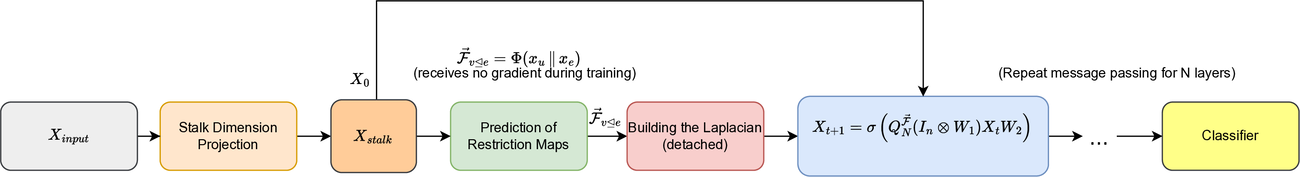

*The DSHN-Light architecture: input features are projected to stalks, restriction maps are predicted once and used to build a detached directed sheaf hypergraph Laplacian, and N message-passing layers X_{t+1} = sigma(Q_N (I kron W1) X_t W2) are applied before the classifier.*

<sub>Source: Mule et al. (2025), *Directional Sheaf Hypergraph Networks: Unifying Learning on Directed and Undirected Hypergraphs*, [arXiv:2510.04727](https://arxiv.org/abs/2510.04727), appendix. Reproduced for teaching with attribution (CC BY 4.0).</sub>

<a id="4-dataset-pipeline"></a>
# 4. Dataset Pipeline

We reuse the toy of notebook 8: two overlapping hyperedges that share node 2, now with directions. In $e_0$, nodes 0 and 1 act on node 2; in $e_1$, nodes 2 and 3 act on nodes 4 and 5. Node 2 is a **head** of $e_0$ and a **tail** of $e_1$, so information can flow through it from one group to the next.

Incidence [node, hyperedge]:
 tensor([[0, 1, 2, 2, 3, 4, 5],
        [0, 0, 0, 1, 1, 1, 1]])


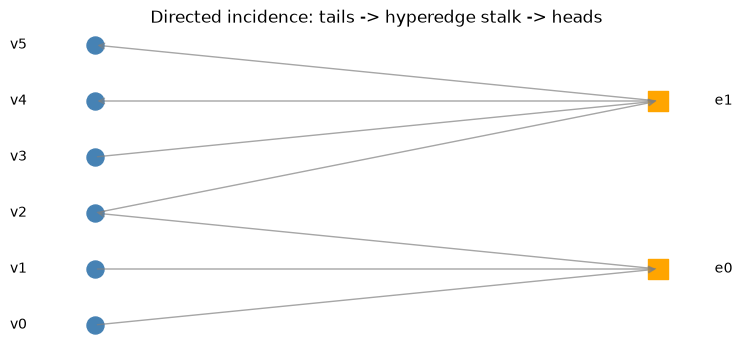

Identity-map hyperedge means: [2.0, 1.0]
Head-minus-tail residual:     [1.5, 0.0]


In [3]:
# =====================================================================
# Two overlapping directed hyperedges
# =====================================================================
groups = [[0, 1, 2], [2, 3, 4, 5]]
tails, heads = [[0, 1], [2, 3]], [[2], [4, 5]]
num_nodes, num_hyperedges = 6, len(groups)
incidence = torch.tensor([(v, e) for e, group in enumerate(groups) for v in group]).T
node_signal = torch.tensor([[1.0], [2.0], [3.0], [-1.0], [0.0], [2.0]])
for e in range(num_hyperedges):
    assert sorted(tails[e] + heads[e]) == sorted(groups[e]) and not set(tails[e]) & set(
        heads[e]
    )
print("Incidence [node, hyperedge]:\n", incidence)

fig, ax = plt.subplots(figsize=(8, 4))
for v in range(num_nodes):
    ax.scatter(0, v, s=150, color="steelblue", zorder=3)
    ax.text(-0.12, v, f"v{v}", ha="right", va="center")
for e, group in enumerate(groups):
    center = 1 + 3 * e
    ax.scatter(1, center, marker="s", s=220, color="orange", zorder=3)
    ax.text(1.1, center, f"e{e}", va="center")
    for v in group:
        start, end = ((0, v), (1, center)) if v in tails[e] else ((1, center), (0, v))
        ax.annotate(
            "",
            xy=end,
            xytext=start,
            arrowprops=dict(arrowstyle="->", color="gray", alpha=0.7),
        )
ax.set_title("Directed incidence: tails -> hyperedge stalk -> heads")
ax.axis("off")
plt.show()

# Scalar reference values (identity maps), kept from the original walkthrough.
edge_mean = torch.stack([node_signal[g].mean(0) for g in groups])
tail_mean = torch.stack([node_signal[t].mean(0) for t in tails])
head_mean = torch.stack([node_signal[h].mean(0) for h in heads])
print("Identity-map hyperedge means:", edge_mean.flatten().tolist())
print("Head-minus-tail residual:    ", (head_mean - tail_mean).flatten().tolist())
assert torch.allclose(edge_mean.flatten(), torch.tensor([2.0, 1.0]))
assert torch.allclose((head_mean - tail_mean).flatten(), torch.tensor([1.5, 0.0]))

<a id="5-reference"></a>
# 5. Reference Computations

<a id="building"></a>
### 5.1 Building the Directed Laplacian

The function below builds $\mathbf{B}^{(q)}$ and $\mathbf{L}^{\vec{\mathcal{F}}} = \mathbf{D}_V - \mathbf{B}^{\dagger}\mathbf{D}_E^{-1}\mathbf{B}$ exactly as defined in Section 3.2, with real restriction maps `maps[(v, e)]` and complex phases on the tails. It is a direct transcription of the definition, written for clarity rather than efficiency. A real layer would never build these dense matrices.

In [4]:
# =====================================================================
# Dense Directed Sheaf Hypergraph Laplacian
# =====================================================================
def directional_incidence(groups, tails, maps, n, d, q):
    B = torch.zeros(len(groups) * d, n * d, dtype=torch.complex128)
    phase = torch.exp(torch.tensor(-2j * np.pi * q))
    for e, g in enumerate(groups):
        for v in g:
            block = maps[(v, e)].to(torch.complex128)
            if v in tails[e]:
                block = phase * block
            B[e * d : (e + 1) * d, v * d : (v + 1) * d] = block
    return B


def directed_sheaf_laplacian(groups, tails, maps, n, d, q):
    B = directional_incidence(groups, tails, maps, n, d, q)
    D_E_inv = torch.block_diag(
        *[torch.eye(d, dtype=torch.complex128) / len(g) for g in groups]
    )
    D_V = torch.zeros(n * d, n * d, dtype=torch.complex128)
    for e, g in enumerate(groups):
        for v in g:
            F = maps[(v, e)].to(torch.complex128)
            D_V[v * d : (v + 1) * d, v * d : (v + 1) * d] += (
                F.T @ F
            )  # the phase cancels in F^dagger F
    return D_V - B.conj().T @ D_E_inv @ B


def undirected_sheaf_hypergraph_laplacian(groups, maps, n, d):
    """Operator form of notebook 8 (diagonal (delta_e - 1)/delta_e)."""
    L = torch.zeros(n * d, n * d)
    for e, g in enumerate(groups):
        for v in g:
            for u in g:
                if u != v:
                    L[v * d : (v + 1) * d, v * d : (v + 1) * d] += (
                        maps[(v, e)].T @ maps[(v, e)] / len(g)
                    )
                    L[v * d : (v + 1) * d, u * d : (u + 1) * d] -= (
                        maps[(v, e)].T @ maps[(u, e)] / len(g)
                    )
    return L


torch.manual_seed(0)
d = 2
maps = {(v, e): torch.randn(d, d) for e, g in enumerate(groups) for v in g}
L_q = directed_sheaf_laplacian(groups, tails, maps, num_nodes, d, q=0.25)
print(
    f"Shape: {tuple(L_q.shape)} (complex), off-diagonal blocks complex: {L_q.imag.abs().max() > 0}"
)

Shape: (12, 12) (complex), off-diagonal blocks complex: True


<a id="properties"></a>
### 5.2 Properties and Special Cases

Any implementation of a directed sheaf hypergraph layer should pass the following checks.
1. **Hermitian and positive semi-definite:** $\mathbf{L} = \mathbf{L}^{\dagger}$ with real, non-negative eigenvalues. This is what makes it a valid diffusion operator with a spectral (Fourier) interpretation.
2. **No direction at $q = 0$:** the operator equals the undirected sheaf hypergraph Laplacian of notebook 8.
3. **Reversal is conjugation:** swapping every tail set with its head set gives $\overline{\mathbf{L}}$, with the same spectrum and conjugated eigenvectors. The direction lives in the phases, not in the eigenvalues.
4. **Graphs:** when every hyperedge is a single directed edge (one tail, one head, $\delta_e = 2$) and the maps are trivial, the operator equals **one half of the magnetic Laplacian** $D_s - A_s \odot e^{i 2\pi q (A - A^{\top})}$ of notebook 3.

In [5]:
# =====================================================================
# Checks 1-4
# =====================================================================
eig = torch.linalg.eigvalsh(L_q)
print(
    f"1. Hermitian: {torch.allclose(L_q, L_q.conj().T)} | min eigenvalue {eig.min():.2e} (>= 0 up to rounding)"
)

L_0 = directed_sheaf_laplacian(groups, tails, maps, num_nodes, d, q=0.0)
L_und = undirected_sheaf_hypergraph_laplacian(groups, maps, num_nodes, d)
print(
    f"2. q = 0 equals the undirected operator: {torch.allclose(L_0.real.float(), L_und, atol=1e-4)} "
    f"(imaginary part zero: {L_0.imag.abs().max() < 1e-12})"
)

L_rev = directed_sheaf_laplacian(
    groups, heads, maps, num_nodes, d, q=0.25
)  # heads become tails
print(f"3. Reversed directions == conjugate: {torch.allclose(L_rev, L_q.conj())}")

# 4. Directed graph as a 2-uniform directed hypergraph with trivial maps.
cycle = [(0, 1), (1, 2), (2, 3), (3, 0)]
g_groups, g_tails = [[u, v] for u, v in cycle], [[u] for u, _ in cycle]
trivial = {(v, e): torch.eye(1) for e, g in enumerate(g_groups) for v in g}
L_graph = directed_sheaf_laplacian(g_groups, g_tails, trivial, 4, 1, q=0.1)
A = torch.zeros(4, 4, dtype=torch.float64)
for u, v in cycle:
    A[u, v] = 1.0
A_s = ((A + A.T) > 0).to(torch.float64)
magnetic = torch.diag(A_s.sum(1)).to(torch.complex128) - A_s * torch.exp(
    1j * 2 * np.pi * 0.1 * (A - A.T)
)
print(
    f"4. Directed cycle: L == magnetic Laplacian / 2: {torch.allclose(L_graph, magnetic / 2)}"
)

1. Hermitian: True | min eigenvalue -7.52e-16 (>= 0 up to rounding)
2. q = 0 equals the undirected operator: True (imaginary part zero: True)
3. Reversed directions == conjugate: True
4. Directed cycle: L == magnetic Laplacian / 2: True


<a id="charge-and-flow"></a>
### 5.3 Charge, Spectrum, and Net Flow

The charge $q$ controls how strongly direction enters the operator. As in notebook 3, the spectrum depends on $q$ only through **cycles**, here cycles of the *incidence graph*, the bipartite graph between nodes and hyperedges. When that graph is a tree, every phase can be absorbed by multiplying each node's coordinate by a unit complex number (a gauge transformation), and the spectrum does not depend on $q$ at all. Our toy is such a tree: two hyperedges that share a single node.

At $q = 1/4$ the phases are $\pm i$, and the paper shows that $\operatorname{Im}(\mathbf{L})_{uv}$ then measures the **net flow** between $u$ and $v$: tail-to-head pairs contribute $-1/\delta_e$ and head-to-tail pairs $+1/\delta_e$, while tail-tail and head-head pairs only contribute to the real part. The heatmap below shows this sign pattern for the toy with trivial maps.

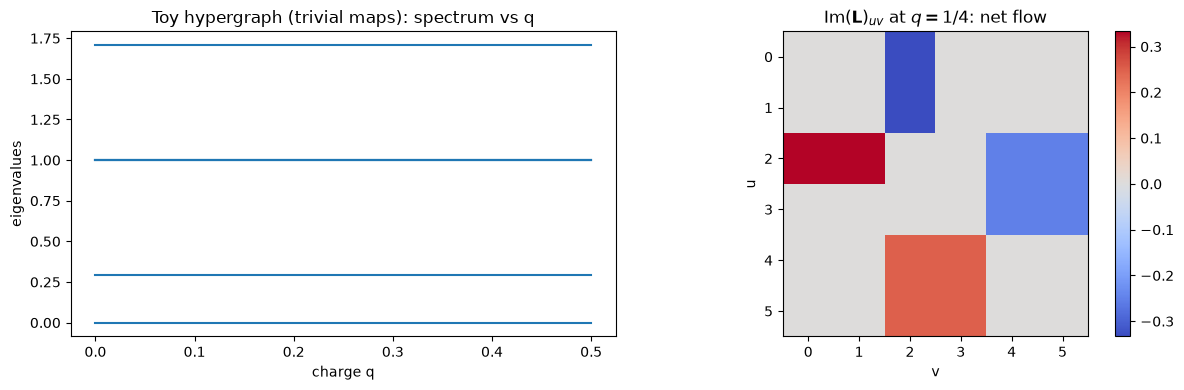

Row 2 (the shared node): [0.333, 0.333, 0.0, 0.0, -0.25, -0.25]


In [6]:
# =====================================================================
# Spectrum vs charge, and the net-flow pattern at q = 1/4
# =====================================================================
trivial_toy = {(v, e): torch.eye(1) for e, g in enumerate(groups) for v in g}
qs = np.linspace(0, 0.5, 41)
spectra = np.array(
    [
        torch.linalg.eigvalsh(
            directed_sheaf_laplacian(groups, tails, trivial_toy, num_nodes, 1, q)
        ).numpy()
        for q in qs
    ]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(qs, spectra, color="tab:blue")
axes[0].set(
    xlabel="charge q",
    ylabel="eigenvalues",
    title="Toy hypergraph (trivial maps): spectrum vs q",
)

flow = directed_sheaf_laplacian(
    groups, tails, trivial_toy, num_nodes, 1, q=0.25
).imag.numpy()
lim = np.abs(flow).max()
im = axes[1].imshow(flow, cmap="coolwarm", vmin=-lim, vmax=lim)
axes[1].set(
    xticks=range(num_nodes),
    yticks=range(num_nodes),
    xlabel="v",
    ylabel="u",
    title=r"Im$(\mathbf{L})_{uv}$ at $q = 1/4$: net flow",
)
plt.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()
print("Row 2 (the shared node):", np.round(flow[2], 3).tolist())

Read row 2 of the heatmap. Node 2 is a head of $e_0$ (nodes 0 and 1 flow *into* it) and a tail of $e_1$ (it flows *into* nodes 4 and 5). The imaginary part has opposite signs for these two groups of partners: the operator records that information enters node 2 from one side and leaves it on the other. Its partner in the tail of $e_1$ (node 3) only appears in the real part.

The spectrum is flat, as the gauge argument predicts for a tree-shaped incidence graph, yet the operator is clearly directional: the phases are visible in the eigenvectors and in the net-flow pattern, and reversing the directions conjugates them (Section 5.2). Exercise 3 adds a cycle, after which the eigenvalues themselves start to move with $q$. With learned restriction maps, as in DSHN, the maps and the phases interact, which is what the model exploits.

<a id="6-backbone"></a>
# 6. Model Backbone (TODO)

Design a directed sheaf hypergraph layer. The checks of Section 5.2 give you a test suite. The key decision, which the reference computations make explicit, is **where the phases enter**. A real-valued layer can split the complex operator into its real and imaginary parts (doubling the channels), or it can run complex arithmetic end to end and take the real part at the output. Choose one, document it, and keep the direction visible. A layer that only uses $|\mathbf{L}|$ throws the phases away and cannot tell a reaction from its reverse.

Suggested order:
1. `restriction_maps`: one real map per incidence, from the node feature and a hyperedge summary.
2. `node_to_hyperedge`: build $\mathbf{B}^{(q)}\mathbf{x}$, with the phase on tail incidences, and divide by $\delta_e$.
3. `hyperedge_to_node`: apply $\mathbf{B}^{(q)\dagger}$ and the node-degree normalization, so that one step equals $\mathbf{Q}_N\mathbf{x}$ with $\mathbf{L}_N = I - \mathbf{Q}_N$.
4. `forward`: $\mathbf{X}^{+} = \sigma\big(\mathbf{Q}_N (I \otimes W_1)\mathbf{X}W_2\big)$ as in DSHN, then decide how the complex result becomes real features.

In [7]:
class HypergraphSheafLayer(torch.nn.Module):
    def __init__(self, stalk_dim=2, hidden_dim=8):
        super().__init__()
        self.stalk_dim, self.hidden_dim = stalk_dim, hidden_dim
        # TODO: register trainable incidence-map learner and feature transforms.

    def restriction_maps(self, x_stalk, incidence):
        """Input [N,d,f], [2,I]; return one [d,d] map per incidence."""
        raise NotImplementedError("TODO: learn maps from node and hyperedge context")

    def node_to_hyperedge(self, x_stalk, incidence, maps):
        """Return transported, normalized hyperedge states [M,d,f]."""
        raise NotImplementedError("TODO: scatter transported incidence features")

    def hyperedge_to_node(self, edge_stalk, incidence, maps):
        """Return aggregated node messages [N,d,f]."""
        raise NotImplementedError("TODO: pull back messages; normalize degrees")

    def forward(self, x_stalk, incidence, tails=None, heads=None):
        # TODO: put the phase e^{-2 pi i q} on tail incidences, aggregate tails and heads,
        # and decide explicitly how the complex result is turned back into real features.
        raise NotImplementedError(
            "TODO: compose transport, aggregation, residual update"
        )


class HypergraphSheafModel(torch.nn.Module):
    def __init__(self, in_channels=1, out_channels=2, stalk_dim=2, hidden_dim=8):
        super().__init__()
        self.stalk_dim, self.hidden_dim = stalk_dim, hidden_dim
        self.encoder = torch.nn.Linear(in_channels, stalk_dim * hidden_dim)
        self.layer = HypergraphSheafLayer(stalk_dim, hidden_dim)
        self.decoder = torch.nn.Linear(stalk_dim * hidden_dim, out_channels)

    def forward(self, x, incidence, tails=None, heads=None):
        h = self.encoder(x).reshape(-1, self.stalk_dim, self.hidden_dim)
        h = self.layer(h, incidence, tails=tails, heads=heads)
        return self.decoder(h.reshape(x.size(0), -1))


backbone = HypergraphSheafModel()
print(backbone)
print("Backbone only: the forward pass is intentionally TODO.")

HypergraphSheafModel(
  (encoder): Linear(in_features=1, out_features=16, bias=True)
  (layer): HypergraphSheafLayer()
  (decoder): Linear(in_features=16, out_features=2, bias=True)
)
Backbone only: the forward pass is intentionally TODO.


<a id="7-training"></a>
# 7. Training Pipeline (TODO)

1. Generate labels from a rule that depends on direction, for example "a node's label is the majority class of the *tails* of the hyperedges it heads", then define disjoint node masks.
2. Implement the layer and verify it against Section 5.2: Hermitian, positive semi-definite, the undirected limit at $q = 0$, conjugation under reversal, and the magnetic Laplacian on directed graphs.
3. Add Adam, masked cross-entropy, validation-based checkpoint selection, and a single held-out test evaluation.
4. Compare $q = 0$ (direction ignored) with $q = 1/4$. On a direction-dependent task, the gap measures how much your layer actually uses direction.

No model scores are supplied, because this backbone has not been implemented.

In [8]:
RUN_STUDENT_IMPLEMENTATION = False
if RUN_STUDENT_IMPLEMENTATION:
    # TODO: implement the layer before enabling this exercise.
    logits = backbone(node_signal, incidence, tails=tails, heads=heads)
    assert logits.shape == (num_nodes, 2)

<a id="8-exercises"></a>
# 8. Reproducibility and Exercises

Record the seed, the hyperedge membership with its tails and heads, the charge $q$, the normalization, the stalk widths, and the update rule. Test node and hyperedge permutations, duplicate incidences, hyperedges with empty tails (they must behave as undirected), singleton hyperedges, isolated nodes, finite gradients, and device transfers. **Reverse every tail and head set** as a test: a layer that really uses direction must respond to it, since the operator is conjugated (Section 5.2).

**Key takeaways**
* A directed hyperedge relates a tail set to a head set and generalizes both directed edges and undirected hyperedges.
* Putting the phase $e^{-2\pi i q}$ on tail incidences yields a Hermitian, positive semi-definite Laplacian that reduces to the undirected sheaf hypergraph Laplacian at $q = 0$ and to the magnetic Laplacian on directed graphs.
* Direction lives in the phases: reversing every hyperedge conjugates the operator and leaves its spectrum unchanged.

### Exercises
1. Explain how node 2 couples the two groups, and what changes if it becomes a tail of $e_0$ as well.
2. Using `out_neighbourhood_hyperedges`, convert the directed cycle of notebook 3 into a directed hypergraph. Compare its spectrum against $q$ with that of the magnetic Laplacian.
3. Add a third hyperedge that closes a directed loop through the toy. How does the spectrum now depend on $q$?
4. Implement the TODO layer with diagonal maps and test whether it distinguishes the toy from its reversed version.
5. Extension: give the hyperedges weights $w_e$ (DSHN supports them) and work out where they enter $\mathbf{B}$ and $\mathbf{D}_E$.